In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../data/olist.db")
plt.rcParams["figure.figsize"] = (9, 5)

Matplotlib is building the font cache; this may take a moment.


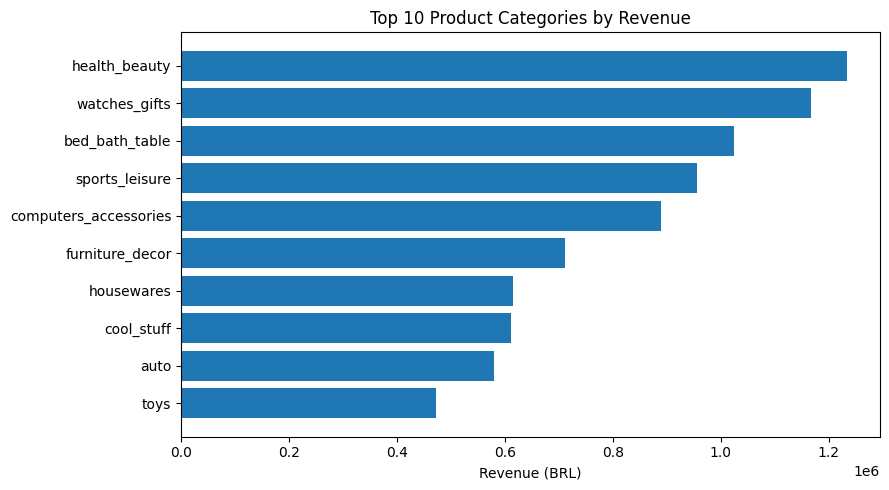

In [2]:
df = pd.read_sql("""
SELECT p.product_category_name_english AS category,
       ROUND(SUM(i.price), 2) AS revenue
FROM items i
JOIN orders o   ON o.order_id = i.order_id
JOIN products p ON p.product_id = i.product_id
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY revenue DESC
LIMIT 10;
""", conn)

plt.barh(df["category"][::-1], df["revenue"][::-1])
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.tight_layout()
plt.savefig("../dashboard/01_top_categories.png", dpi=150)
plt.show()

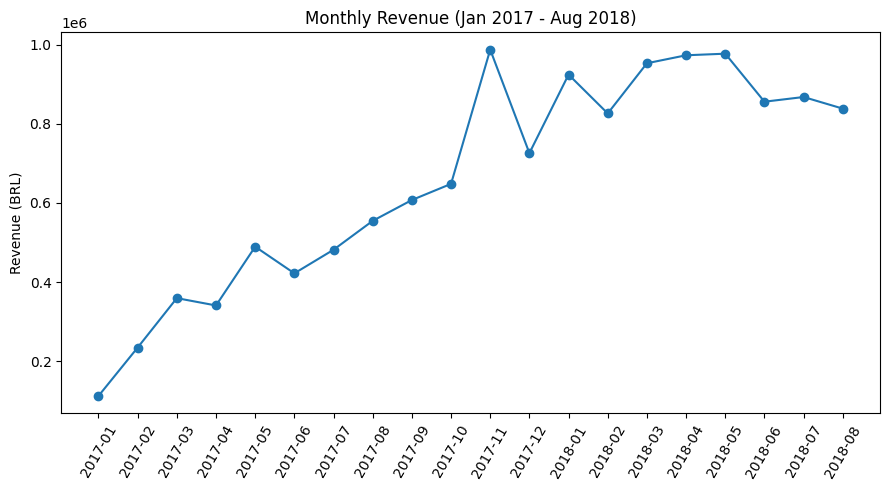

In [3]:
df = pd.read_sql("""
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       ROUND(SUM(i.price), 2) AS revenue
FROM orders o
JOIN items i ON i.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY month
ORDER BY month;
""", conn)

df = df[(df["month"] >= "2017-01") & (df["month"] <= "2018-08")]

plt.plot(df["month"], df["revenue"], marker="o")
plt.xticks(rotation=60)
plt.title("Monthly Revenue (Jan 2017 - Aug 2018)")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.savefig("../dashboard/02_monthly_revenue.png", dpi=150)
plt.show()

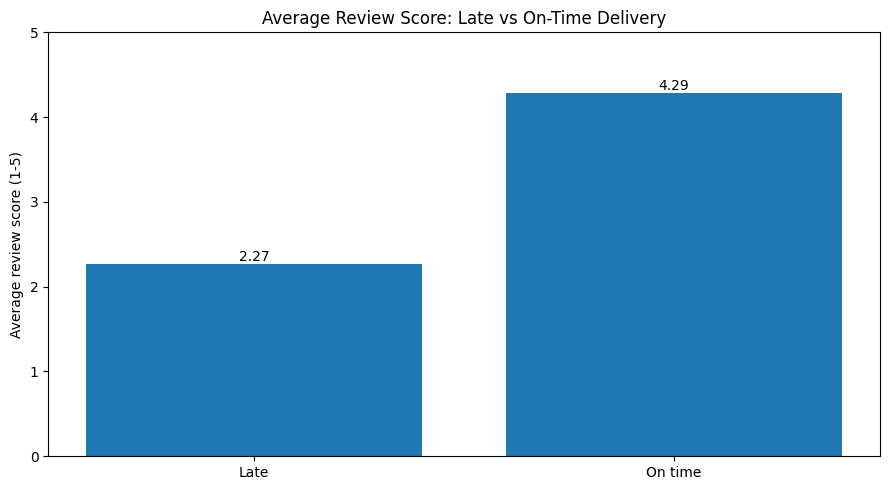

In [4]:
df = pd.read_sql("""
SELECT CASE WHEN o.is_late = 1 THEN 'Late' ELSE 'On time' END AS delivery,
       ROUND(AVG(r.review_score), 2) AS avg_review_score
FROM orders o
JOIN reviews r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered' AND o.is_late IS NOT NULL
GROUP BY delivery;
""", conn)

bars = plt.bar(df["delivery"], df["avg_review_score"])
plt.bar_label(bars, fmt="%.2f")
plt.ylim(0, 5)
plt.title("Average Review Score: Late vs On-Time Delivery")
plt.ylabel("Average review score (1-5)")
plt.tight_layout()
plt.savefig("../dashboard/03_late_vs_reviews.png", dpi=150)
plt.show()

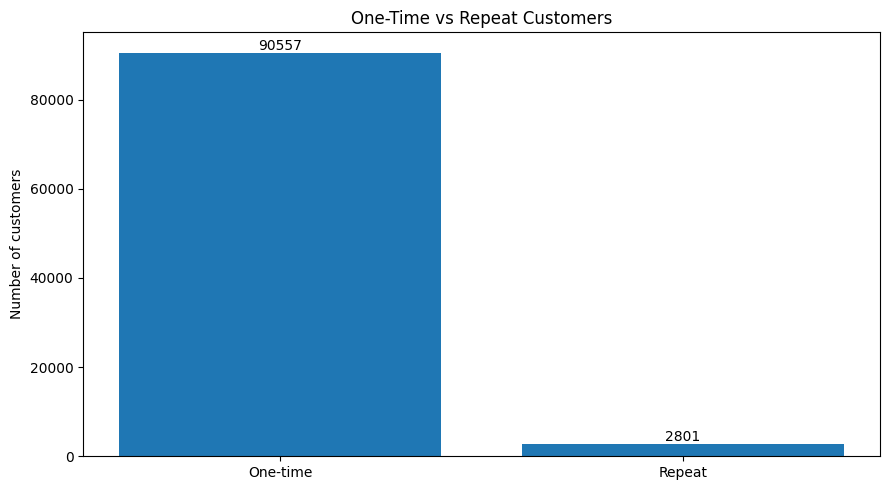

In [5]:
df = pd.read_sql("""
WITH cust AS (
    SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS n_orders
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)
SELECT CASE WHEN n_orders = 1 THEN 'One-time' ELSE 'Repeat' END AS customer_type,
       COUNT(*) AS customers
FROM cust
GROUP BY customer_type;
""", conn)

bars = plt.bar(df["customer_type"], df["customers"])
plt.bar_label(bars)
plt.title("One-Time vs Repeat Customers")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.savefig("../dashboard/04_repeat_customers.png", dpi=150)
plt.show()

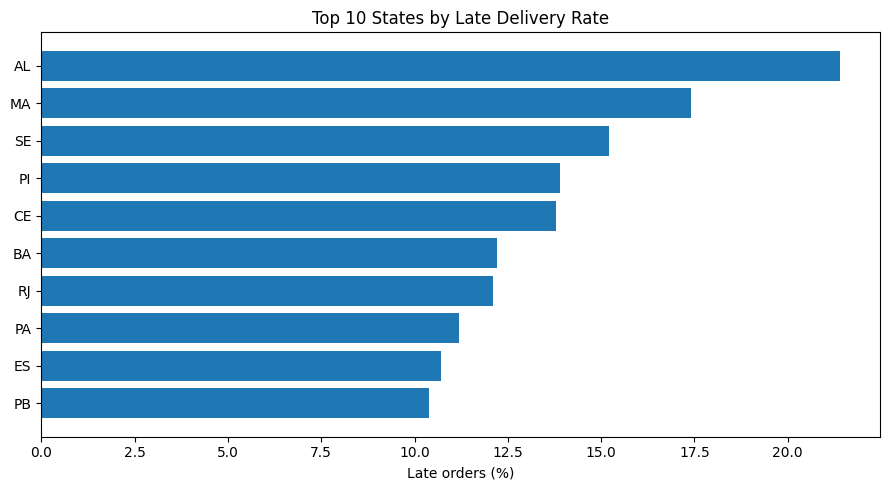

In [6]:
df = pd.read_sql("""
SELECT c.customer_state AS state,
       ROUND(100.0 * AVG(o.is_late), 1) AS late_pct
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered' AND o.is_late IS NOT NULL
GROUP BY c.customer_state
HAVING COUNT(*) >= 100
ORDER BY late_pct DESC
LIMIT 10;
""", conn)

plt.barh(df["state"][::-1], df["late_pct"][::-1])
plt.title("Top 10 States by Late Delivery Rate")
plt.xlabel("Late orders (%)")
plt.tight_layout()
plt.savefig("../dashboard/05_late_by_state.png", dpi=150)
plt.show()

In [7]:
readme = """# Olist E-Commerce Sales & Delivery Analysis

An end-to-end analysis of 99,000+ orders from the Brazilian e-commerce marketplace Olist (Sep 2016 - Aug 2018). I cleaned raw data with pandas, stored it in SQLite, answered business questions with SQL, and visualised the results.

## Business questions
1. Which product categories drive the most revenue?
2. How did revenue change over time?
3. Does late delivery hurt customer reviews?
4. How many customers come back?
5. Which regions have the worst delivery performance?

## Key findings

**1. Revenue is led by a few categories.** Health & beauty (about 1.23M BRL), watches & gifts (about 1.17M BRL) and bed, bath & table (about 1.02M BRL) are the top three.

![Top categories](dashboard/01_top_categories.png)

**2. Growth peaked in Nov 2017 and then flattened.** Revenue reached about 988K BRL in Nov 2017 (+52% vs the previous month), then stayed between roughly 830K and 980K a month through 2018.

![Monthly revenue](dashboard/02_monthly_revenue.png)

**3. Late delivery sharply lowers review scores.** Only about 6.8% of orders arrive late, but they average a review of 2.27, compared with 4.29 for on-time orders.

![Late vs reviews](dashboard/03_late_vs_reviews.png)

**4. Retention is very low.** 97% of customers (90,557) bought only once; just 3% (2,801) returned.

![Repeat customers](dashboard/04_repeat_customers.png)

**5. Late deliveries cluster in the Northeast and Rio de Janeiro.** Alagoas (21.4%), Maranhao (17.4%) and Sergipe (15.2%) have the highest late rates, versus 4.5% in Sao Paulo. Rio de Janeiro has 12.1% late across 12,350 orders.

![Late by state](dashboard/05_late_by_state.png)

## Recommendations
- Prioritise logistics improvements in the Northeast states and Rio de Janeiro, where late deliveries are most concentrated.
- Proactively contact customers whose orders are running late, since late delivery is linked to much lower reviews.
- Test retention efforts (follow-up offers, review-based outreach), because repeat purchases are only 3%.

## Method
1. **Cleaning (pandas):** converted dates, handled missing values, translated product categories, removed duplicate reviews, created delivery-time and lateness metrics.
2. **Storage:** loaded the cleaned tables into a SQLite database.
3. **Analysis (SQL):** joins across multiple tables, CTEs, window functions (LAG) and HAVING filters. Queries are in the `sql/` folder.
4. **Visualisation:** matplotlib charts in the `dashboard/` folder.

## Assumptions and limitations
- Revenue means item price only (freight excluded) on delivered orders.
- "Late" means delivered after Olist's estimated delivery date. Remote states can show long delivery times but low late rates because their estimates are longer.
- The link between late delivery and low reviews is an association, not proof of cause.
- 2016 and the final months of the data are incomplete, so trend analysis is limited to Jan 2017 - Aug 2018.
- Unique customers are identified by `customer_unique_id`, not `customer_id`.

## Tools
Python, pandas, SQLite, SQL, matplotlib, Jupyter Notebook

## Project structure

    olist-sales-analysis/
    |-- notebooks/    data loading, cleaning, analysis and charts
    |-- sql/          one query file per business question
    |-- dashboard/    chart images
    |-- README.md

## How to reproduce
1. Download the dataset from Kaggle: "Brazilian E-Commerce Public Dataset by Olist".
2. Extract the CSV files into a `data/` folder.
3. Run the notebooks in order: 01, 02, 03.

## Author
Aashika Anil N | [GitHub](https://github.com/ashcore-03)
"""

with open("../README.md", "w", encoding="utf-8") as f:
    f.write(readme)

with open("../.gitignore", "w", encoding="utf-8") as f:
    f.write("data/\n.ipynb_checkpoints/\n")

import os
print(sorted(os.listdir("..")))

['.gitignore', 'README.md', 'dashboard', 'data', 'notebooks', 'sql']
